In [1]:
import os
import random
from glob import glob

import matplotlib.pyplot as plt
import numpy as np
#pip install split-folders
import splitfolders

from IPython.display import display
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.applications.densenet import (DenseNet121,
                                                    preprocess_input)
from tensorflow.keras.callbacks import LearningRateScheduler
from tensorflow.keras.layers import (BatchNormalization, Dense,
                                     Dropout, Flatten, Input)
from tensorflow.keras.metrics import Precision, Recall
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [10]:
data_dir = './Data_subsets/train/'
DATASET_PATH = './Data_subsets/train/'
dir_list = os.listdir(DATASET_PATH)
print(dir_list)

['CANCER', 'NON CANCER']


In [11]:
num_of_images = []
for root, dirs, files in os.walk(DATASET_PATH):
    if root == DATASET_PATH: continue
    print('{}: {}'.format(os.path.basename(root), len(files)))
    num_of_images.append(len(files))

CANCER: 350
NON CANCER: 175


In [12]:
num_of_images = []
for root, dirs, files in os.walk(DATASET_PATH):
    if root == DATASET_PATH: continue
    print('{}: {}'.format(os.path.basename(root), len(files)))
    num_of_images.append(len(files))

CANCER: 350
NON CANCER: 175


path: ./Data_subsets/train\CANCER\421.jpeg
size: (619, 410)
mode: P
format: PNG


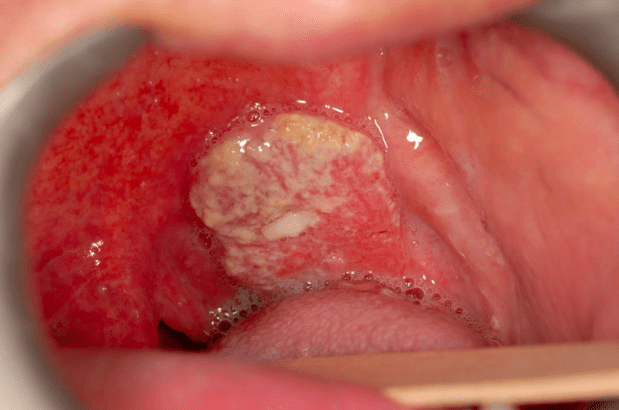

In [13]:
SEED = 23
random.seed(SEED)
rand_img = Image.open(random.choice(glob(DATASET_PATH + '/**/*')))

print('path:', rand_img.filename)
print('size:', rand_img.size)
print('mode:', rand_img.mode)
print('format:', rand_img.format)
display(rand_img)

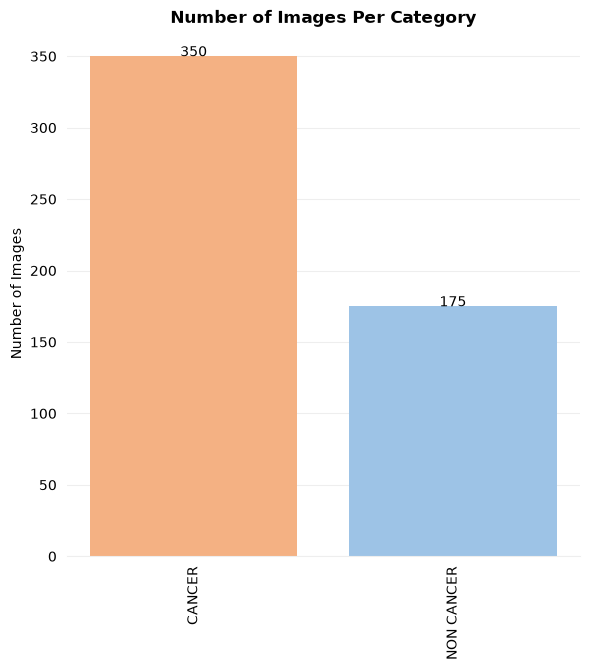

In [14]:
# Plot the number of images per subdirectory
x_coord = np.arange(len(dir_list))
colors = ['#f4b183', '#9dc3e6']

fig, ax = plt.subplots(facecolor='white', figsize=(6,6))
ax.bar(x_coord, num_of_images, color=colors)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#EEEEEE')

ax.yaxis.grid(True, color='#EEEEEE')
ax.set_axisbelow(True)

plt.xticks(x_coord, dir_list)
ax.tick_params(bottom=False, left=False)

plt.title('Number of Images Per Category', fontweight='bold')
plt.ylabel('Number of Images')

for i in range(len(x_coord)):
    plt.text(i, num_of_images[i], num_of_images[i], ha='center')

plt.tight_layout()
plt.savefig('bar_chart.png', dpi=200)
plt.xticks(rotation=90)
plt.show()

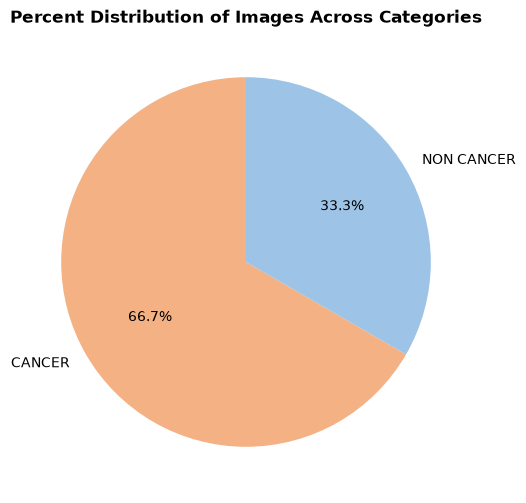

In [15]:
# Plot the percent distribution of images across subdirectories
plt.figure(facecolor='white', figsize=(6,6))
plt.pie(num_of_images,
        labels=dir_list,
        colors=colors,
        autopct='%.1f%%',
        startangle=90)
plt.title('Percent Distribution of Images Across Categories', fontweight='bold')
plt.savefig('pie_chart.png', dpi=200)
plt.show()

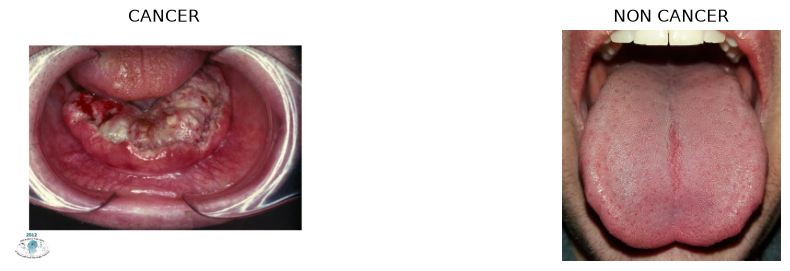

In [16]:
# Display random images, one from each category
plt.figure(facecolor='white', figsize=(12,3))
for i in range(2):
    ax = plt.subplot(1, 2, i + 1)
    path = random.choice(glob(DATASET_PATH + '/' + dir_list[i] + '/*'))
    plt.imshow(Image.open(path), cmap='gray')
    plt.title(dir_list[i])
    plt.axis('off')
plt.savefig('random_images.png', dpi=200)
plt.show()

In [17]:
# Split the dataset folder into test, train, and val folders
OUTPUT_PATH = 'Data_subsets'
if not os.path.exists(OUTPUT_PATH):
    splitfolders.ratio(DATASET_PATH, OUTPUT_PATH, SEED, (.7, .1, .2))

In [18]:
IMG_DIMS = 100
TARGET_SIZE = (IMG_DIMS, IMG_DIMS)
COLOR_MODE = 'rgb'
CLASS_MODE = 'categorical'
BATCH_SIZE = 16

In [19]:
#data preprocessing
TRAIN_PATH = os.path.join(OUTPUT_PATH, 'train')
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=5,
    width_shift_range=0.05,
    height_shift_range=0.05,
    brightness_range=[0.9, 1.1],
    zoom_range=[0.9, 1.1],
    horizontal_flip=True)
train_gen = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=TARGET_SIZE,
    color_mode=COLOR_MODE,
    class_mode=CLASS_MODE,
    batch_size=BATCH_SIZE,
    seed=SEED)

Found 525 images belonging to 2 classes.


In [20]:
# Take the path to the val folder and generate batches of data
VAL_PATH = os.path.join(OUTPUT_PATH, 'val')
val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input)
val_gen = val_datagen.flow_from_directory(
    VAL_PATH,
    target_size=TARGET_SIZE,
    color_mode=COLOR_MODE,
    class_mode=CLASS_MODE,
    batch_size=BATCH_SIZE,
    seed=SEED)

Found 75 images belonging to 2 classes.


In [21]:
# Take the path to the train folder and generate batches of data
TEST_PATH = os.path.join(OUTPUT_PATH, 'test')
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input)
test_gen = test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=TARGET_SIZE,
    color_mode=COLOR_MODE,
    class_mode=CLASS_MODE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    seed=SEED)

Found 150 images belonging to 2 classes.


In [22]:
print(train_gen.directory)
print(val_gen.directory)
print(test_gen.directory)

Data_subsets\train
Data_subsets\val
Data_subsets\test


In [23]:
print(train_gen.class_indices)

{'CANCER': 0, 'NON CANCER': 1}


In [24]:
# Print the shapes of the first training batch tuple
images, labels = next(iter(train_gen))
print('images shape:', images.shape)  # (batch_size, *target_size, channels)
print('labels shape:', labels.shape)  # (batch_size, num_classes)

images shape: (16, 100, 100, 3)
labels shape: (16, 2)


In [25]:
# in the input layer it extracts the features and processed
base_model = DenseNet121(
    include_top=False,
    weights='imagenet',
    input_tensor=Input(shape=(IMG_DIMS, IMG_DIMS, 3)),
    input_shape=(IMG_DIMS, IMG_DIMS, 3))

In [26]:
# Freeze the base model layers
for layer in base_model.layers:
    layer.trainable = False

In [27]:
# Build the modified DenseNet121 model
model = Sequential()
model.add(base_model)
model.add(Flatten())
model.add(BatchNormalization())
model.add(Dense(1024, activation='relu'))
model.add(Dropout(0.4))
model.add(BatchNormalization())
model.add(Dense(512, activation='relu'))
model.add(Dropout(0.4))
model.add(BatchNormalization())
model.add(Dense(256, activation='relu'))
model.add(Dense(2, activation='softmax'))

In [28]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 densenet121 (Functional)    (None, 3, 3, 1024)        7037504   
                                                                 
 flatten (Flatten)           (None, 9216)              0         
                                                                 
 batch_normalization (Batch  (None, 9216)              36864     
 Normalization)                                                  
                                                                 
 dense (Dense)               (None, 1024)              9438208   
                                                                 
 dropout (Dropout)           (None, 1024)              0         
                                                                 
 batch_normalization_1 (Bat  (None, 1024)              4096      
 chNormalization)                                       

In [29]:
# Define hyperparameters
EPOCHS = 5
ETA = 0.0001

In [30]:
METRICS = ['categorical_accuracy', Precision(), Recall()]

In [31]:
# Compile the model
model.compile(optimizer=Adam(ETA),
              loss='categorical_crossentropy',
              metrics=METRICS)

In [32]:
# Create a learning rate scheduler callback
def scheduler(epoch):
    if epoch > 19:
        return ETA * 0.1
    else:
        return ETA
callback = LearningRateScheduler(scheduler)

In [33]:
# Estimate class weights for the unbalanced dataset
cls_wt = compute_class_weight(class_weight='balanced',
                              classes=np.unique(train_gen.labels),
                              y=train_gen.labels)
class_weight = {0: cls_wt[0], 1: cls_wt[1]}
print(class_weight)

{0: 0.75, 1: 1.5}


In [34]:
# Calculate class weights for the unbalanced dataset
cls_wt = compute_class_weight(class_weight='balanced',
                              classes=np.unique(train_gen.classes),
                              y=train_gen.classes)
class_weight = {i: wt for i, wt in enumerate(cls_wt)}  # Convert to dictionary
print(class_weight)

# Compile the model
model.compile(optimizer=Adam(ETA),
              loss='categorical_crossentropy',
              metrics=METRICS)

# Create a learning rate scheduler callback
def scheduler(epoch):
    if epoch > 19:
        return ETA * 0.1
    else:
        return ETA
callback = LearningRateScheduler(scheduler)

# Train the model
history = model.fit(train_gen,
                    epochs=EPOCHS,
                    callbacks=[callback],  # Use square brackets to pass callbacks as a list
                    validation_data=val_gen,
                    class_weight=class_weight)  # Pass the class weights dictionary


{0: 0.75, 1: 1.5}
Epoch 1/5


10/33 [========>.....................] - ETA: 13s - loss: 0.8044 - categorical_accuracy: 0.4250 - precision: 0.4250 - recall: 0.4250

C:\Users\sumit\anaconda3\envs\mlproject\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


33/33 [==============================] - 51s 917ms/step - loss: 0.6049 - categorical_accuracy: 0.6267 - precision: 0.6267 - recall: 0.6267 - val_loss: 0.4756 - val_categorical_accuracy: 0.8133 - val_precision: 0.8133 - val_recall: 0.8133 - lr: 1.0000e-04
Epoch 2/5
33/33 [==============================] - 21s 623ms/step - loss: 0.4296 - categorical_accuracy: 0.7905 - precision: 0.7905 - recall: 0.7905 - val_loss: 0.2983 - val_categorical_accuracy: 0.8933 - val_precision: 0.8933 - val_recall: 0.8933 - lr: 1.0000e-04
Epoch 3/5
33/33 [==============================] - 20s 612ms/step - loss: 0.2904 - categorical_accuracy: 0.8629 - precision: 0.8629 - recall: 0.8629 - val_loss: 0.2537 - val_categorical_accuracy: 0.9067 - val_precision: 0.9067 - val_recall: 0.9067 - lr: 1.0000e-04
Epoch 4/5
33/33 [==============================] - 21s 646ms/step - loss: 0.2868 - categorical_accuracy: 0.8648 - precision: 0.8648 - recall: 0.8648 - val_loss: 0.2372 - val_categorical_accuracy: 0.9067 - val_precis

In [35]:
# Calculate class weights for the unbalanced dataset
cls_wt = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_gen.classes),
    y=train_gen.classes
)
class_weight = {i: wt for i, wt in enumerate(cls_wt)}
print(class_weight)

# Compile the model
model.compile(
    optimizer=Adam(ETA),
    loss='categorical_crossentropy',
    metrics=METRICS
)

# Create a learning rate scheduler callback
def scheduler(epoch):
    if epoch > 19:
        return ETA * 0.1
    else:
        return ETA

callback = LearningRateScheduler(scheduler)

# Train the model
history = model.fit(
    train_gen,
    epochs=7,  # Increased from 5 to 7
    callbacks=[callback],
    validation_data=val_gen,
    class_weight=class_weight
)


{0: 0.75, 1: 1.5}
Epoch 1/7


C:\Users\sumit\anaconda3\envs\mlproject\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


33/33 [==============================] - 47s 866ms/step - loss: 0.2658 - categorical_accuracy: 0.8800 - precision: 0.8833 - recall: 0.8833 - val_loss: 0.2184 - val_categorical_accuracy: 0.9067 - val_precision: 0.9067 - val_recall: 0.9067 - lr: 1.0000e-04
Epoch 2/7
33/33 [==============================] - 21s 611ms/step - loss: 0.2000 - categorical_accuracy: 0.9219 - precision: 0.9219 - recall: 0.9219 - val_loss: 0.2273 - val_categorical_accuracy: 0.8933 - val_precision: 0.8933 - val_recall: 0.8933 - lr: 1.0000e-04
Epoch 3/7
33/33 [==============================] - 19s 573ms/step - loss: 0.2202 - categorical_accuracy: 0.9067 - precision: 0.9067 - recall: 0.9067 - val_loss: 0.2378 - val_categorical_accuracy: 0.9067 - val_precision: 0.9067 - val_recall: 0.9067 - lr: 1.0000e-04
Epoch 4/7
33/33 [==============================] - 20s 594ms/step - loss: 0.1745 - categorical_accuracy: 0.9371 - precision: 0.9371 - recall: 0.9371 - val_loss: 0.2316 - val_categorical_accuracy: 0.9067 - val_precis

In [36]:
def plot_metric_history(metric, val_metric, y_label, title):
    """
    Plots a training history metric.

    :param metric: the metric key
    :param val_metric: the validation metric key
    :param y_label: the y-axis label
    :param title: the title
    :return: None
    """
    plt.figure(facecolor='white', figsize=(8, 6))
    plt.plot(history.history[metric])
    plt.plot(history.history[val_metric])
    plt.ylabel(y_label)
    plt.xlabel('epoch')
    plt.title(title)
    plt.legend(['training', 'validation'])
    plt.savefig(y_label + '.png', dpi=200)
    plt.show()

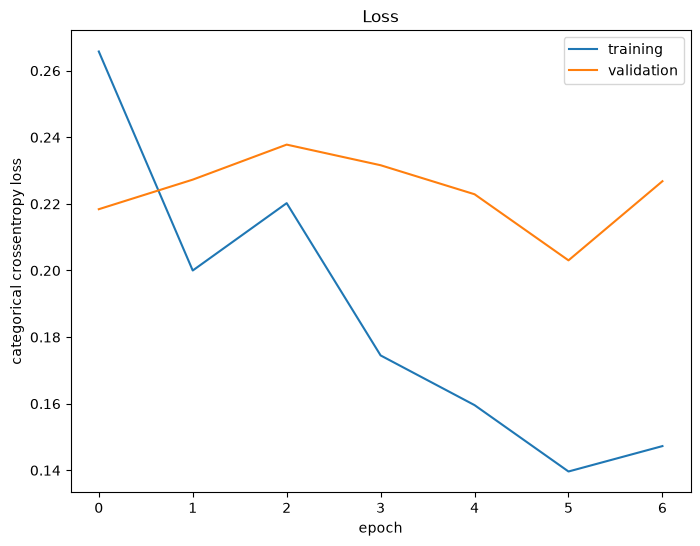

In [37]:
# Visualize loss history
plot_metric_history(metric='loss',
                    val_metric='val_loss',
                    y_label='categorical crossentropy loss',
                    title='Loss')

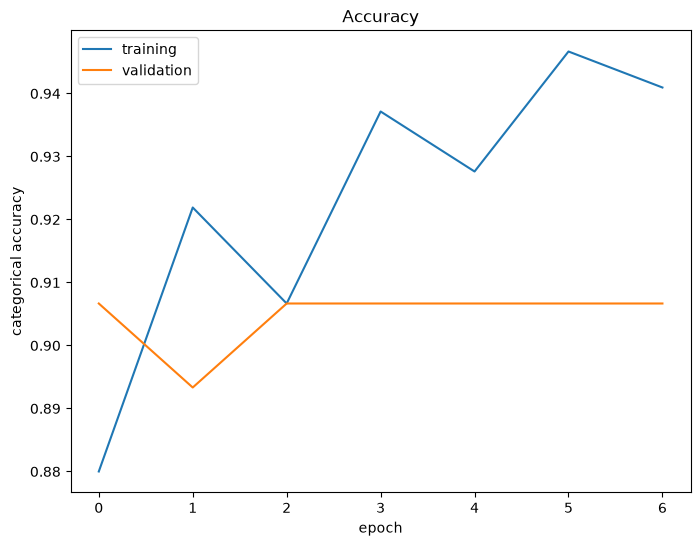

In [38]:
# Visualize accuracy history
plot_metric_history(metric='categorical_accuracy',
                    val_metric='val_categorical_accuracy',
                    y_label='categorical accuracy',
                    title='Accuracy')

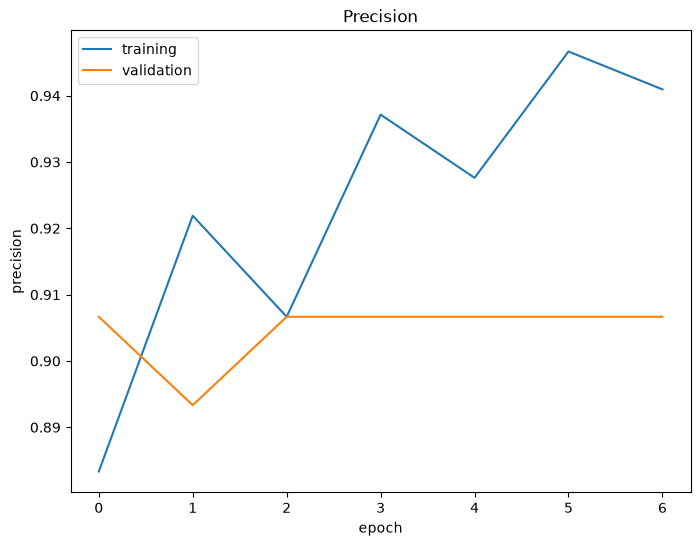

In [39]:
# Visualize precision history
plot_metric_history(metric='precision',
                    val_metric='val_precision',
                    y_label='precision',
                    title='Precision')

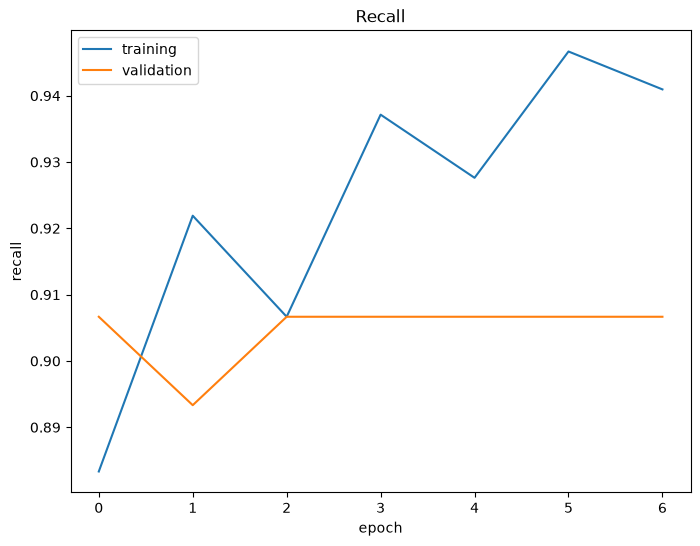

In [40]:
# Visualize recall history
plot_metric_history(metric='recall',
                    val_metric='val_recall',
                    y_label='recall',
                    title='Recall')

In [41]:
# Print metrics values for the model in test mode
result = model.evaluate(test_gen)
dict(zip(model.metrics_names, result))

10/10 [==============================] - 4s 349ms/step - loss: 0.3212 - categorical_accuracy: 0.8467 - precision: 0.8467 - recall: 0.8467


{'loss': 0.32120615243911743,
 'categorical_accuracy': 0.846666693687439,
 'precision': 0.846666693687439,
 'recall': 0.846666693687439}

In [42]:
predictions = model.predict(test_gen)

10/10 [==============================] - 8s 352ms/step


In [43]:
# Initialize true and predicted label values
y_true = test_gen.labels
y_pred = np.argmax(predictions, axis=1)

In [44]:
# Build a text report showing the main classification metrics
report = classification_report(y_true, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.93      0.83      0.88       100
           1       0.72      0.88      0.79        50

    accuracy                           0.85       150
   macro avg       0.83      0.85      0.84       150
weighted avg       0.86      0.85      0.85       150



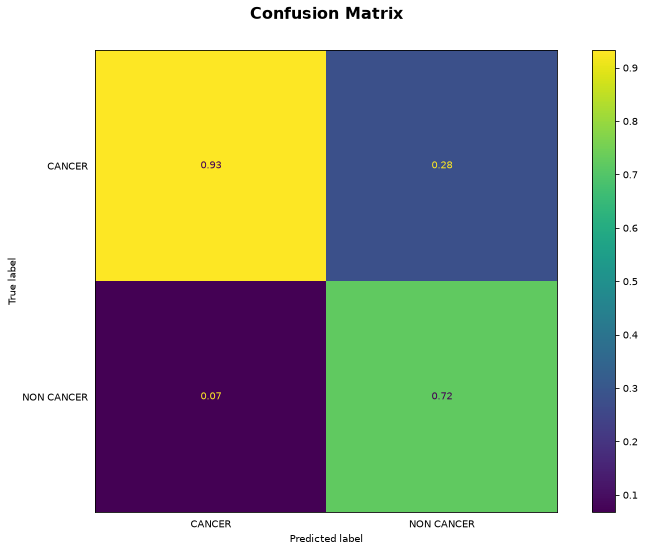

In [45]:
# Plot a confusion matrix given true and predicted labels
fig, ax = plt.subplots(facecolor='white', figsize=(12, 8), dpi=75)
fig = ConfusionMatrixDisplay.from_predictions(y_true,
                                              y_pred,
                                              display_labels=test_gen.class_indices,
                                              include_values=True,
                                              normalize='pred',
                                              values_format='.2f',
                                              cmap='viridis',
                                              ax=ax)
plt.tick_params(left=False, bottom=False)
plt.title('Confusion Matrix', fontsize=15, fontweight='bold', pad=30)
plt.savefig('confusion_matrix.png', dpi=200)
plt.show()

In [46]:
model.save_weights("model.weights.h5")

In [47]:
filepath="model.weights.h5"
model.save(filepath)

C:\Users\sumit\anaconda3\envs\mlproject\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [48]:
from tensorflow.keras.models import load_model
classifier = load_model('model.weights.h5')

In [49]:
def predict(image_path):
    from skimage import io
    from keras.preprocessing import image
    #path='imbalanced/Scratch/Scratch_400.jpg'
    import tensorflow as tf

    img = tf.keras.utils.load_img(image_path,  target_size=(100, 100))
    show_img=tf.keras.utils.load_img(image_path,target_size=(100, 100))
    d_class = ['CANCER', 'No CANCER']
    x = tf.keras.utils.img_to_array(img)
    x = np.expand_dims(x, axis = 0)
    #x = np.array(x, 'float32')
    x /= 255

    custom = classifier.predict(x)
    print(custom[0])



    #x = x.reshape([64, 64]);

    #plt.gray()
    plt.imshow(show_img)
    plt.show()

    a=custom[0]
    ind=np.argmax(a)

    print('Prediction:',d_class[ind])


1/1 [==============================] - 4s 4s/step
[0.48652732 0.5134727 ]


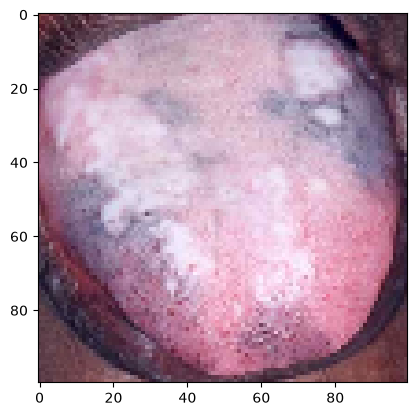

Prediction: No CANCER


In [50]:
predict('./Data_subsets/test/CANCER/149.jpeg')

1/1 [==============================] - 0s 116ms/step
[0.49767584 0.5023241 ]


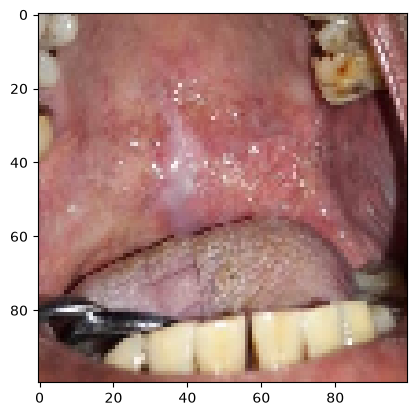

Prediction: No CANCER


In [51]:
predict('./Data_subsets/test/CANCER/221.jpeg')

1/1 [==============================] - 0s 235ms/step
[0.02141497 0.978585  ]


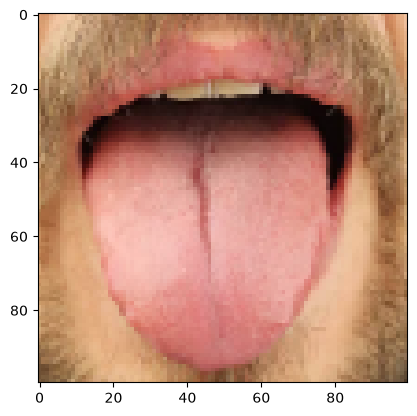

Prediction: No CANCER


In [52]:
predict('./Data_subsets/test/NON CANCER/136.jpeg')

1/1 [==============================] - 0s 87ms/step
[0.00885317 0.99114686]


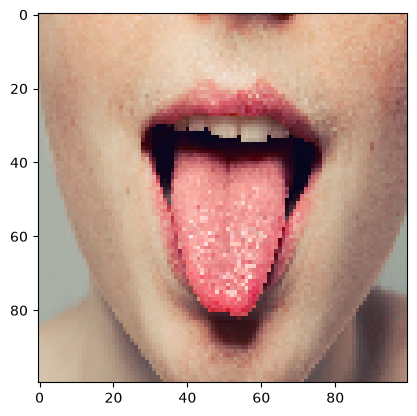

Prediction: No CANCER


In [53]:
predict('./Data_subsets/test/NON CANCER/152.jpeg')